<a href="https://colab.research.google.com/github/Baelfyre/A3101-ml-linear-algebra-project-Team-3/blob/feat%2Fterminal-assessment-finalization/MO-IT162%20Terminal%20Assessment%20-%20ML%20Solution%20Presentation%20-%20BSIT-A1101/MO_IT162_Terminal_Assessment_ML_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FinMark Corporation | Terminal Assessment: ML Solution Evidence Notebook
**MO-IT162 Math for Machine Learning: Linear Algebra | Team 3 | Section A3101**

This notebook integrates Milestone 1 verification, Milestone 2 visual/statistical analysis, and the additional customer purchasing-habits analysis shown in the nine-slide Terminal Assessment presentation. It **does not train or validate Time-Series Forecasting or K-Means models**. The six-month comparison evaluates *two simple forecasting baselines*, not ML algorithms.

**Read in order.** Each finding follows: **business question → method → observed result → interpretation → implication**. Charts are reproduced from verified cleaned CSVs; labels and conclusions avoid claims of causation, profit or model effectiveness.

### Executive summary
- FinMark has verified, internally consistent cleaned customer profiles (2,378), transactions (2,420), and social events (2,411), with incomplete ID overlap and date/provenance concerns that remain unresolved.
- Over 24 months, monthly transaction counts vary (82–121) and category shares are close (18.93%–20.87%); **neither proves profitability or seasonality**.
- Customer-level purchase frequency, total recorded amount and category breadth support *investigating* possible segmentation, not claiming clusters exist.
- Gender-category association is very small, and shared-period social activity has no strong spending association.
- Immediate actions: monitor counts **and amounts**, investigate zero-value/ID/date issues, audit sentiment and context. Conditional longer-term pilots: time-series forecasting and possibly customer clustering, following defined evaluation criteria.

## 1. Scope, evidence, and reproducibility

**Sources and precedence:** The validated Milestone 1 and Milestone 2 notebooks, the Milestone 2 DataViz report and the latest nine-slide Terminal Assessment deck. The source repository is [`Baelfyre/A3101-ml-linear-algebra-project-Team-3`](https://github.com/Baelfyre/A3101-ml-linear-algebra-project-Team-3), reviewed at `main` commit `4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3`. The exact cleaned CSV bytes are supplied in `data/` and checked against the Milestone 2 verified Git blobs. If local data are absent, source loading falls back to the recorded GitHub commit.

**Units and windows:** Transaction-level for monthly counts, category shares and amount distribution (July 2022–June 2024); customer-level for purchase habits and eligible matched-group analyses; interaction-level for sentiment (July 2023–June 2024). The time-aligned transaction/social comparison uses the shared date window and **one row per customer**.

**Key assumptions:** Currency is unspecified. Counts reflect recorded activity, not lifetime customer behavior. No sales margin, promotions, inventory, customer preferences, acquisition cost, or independent future-model test are supplied. Missing cross-file IDs should not be invented. Repeated customer events are not independent people.

**Data provenance:** The Week 3 source performed preprocessing; this notebook **does not silently repeat or change** cleaning. It verifies the supplied cleaned output and documents unresolved questions. Original contaminated files remain available in the course project, not overwritten here.

In [1]:
# @title
# Section 6 | GitHub-only loading, source integrity and data checks
import hashlib
from io import BytesIO
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from IPython.display import display

from pathlib import Path
import os

REPO = 'Baelfyre/A3101-ml-linear-algebra-project-Team-3'
DATA_REF = '4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3'  # verified main commit on 2026-10-31
FOLDER = 'Week3_Preprocessing_Submission'
BASE_URL = f'https://raw.githubusercontent.com/{REPO}/{DATA_REF}/{FOLDER}'

EXPECTED_GIT_BLOBS = {
    'customer_demographics_cleaned.csv': 'f02ede5c0294ee521a8acc9f5918a0f13e240e66',
    'customer_transactions_cleaned.csv': '33a75467e0f31411dbf22a3ce1dcb5b628d7f59b',
    'social_media_interactions_cleaned.csv': '429cb7752d7637944d2cad81136480047fbec0e6',
}

DATA_DIR = Path('data')
FIG_DIR = Path('visualizations')
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_chart(filename):
    plt.gcf().savefig(FIG_DIR / filename, dpi=220, bbox_inches='tight', facecolor='white')

SOURCE_EVIDENCE = []
def load_verified_csv(filename, date_column):
    local_path = DATA_DIR / filename
    if local_path.is_file():
        data = local_path.read_bytes()
        origin = str(local_path)
    else:
        url = f'{BASE_URL}/{filename}'
        try:
            request = Request(url, headers={'User-Agent': 'FinMark-Terminal-Assessment/1.0'})
            with urlopen(request, timeout=30) as response:
                data = response.read()
        except Exception as exc:
            raise RuntimeError(f'Missing local data and GitHub download failed: {filename}: {exc}') from exc
        origin = url
    git_blob_hash = hashlib.sha1(b'blob ' + str(len(data)).encode() + b'\0' + data).hexdigest()
    if git_blob_hash != EXPECTED_GIT_BLOBS[filename]:
        raise ValueError(f'Source bytes changed: {filename}: {git_blob_hash}. Review before accepting new data.')
    frame = pd.read_csv(BytesIO(data), parse_dates=[date_column])
    SOURCE_EVIDENCE.append({'file': filename, 'origin': origin, 'git_blob_sha1': git_blob_hash,
                            'sha256': hashlib.sha256(data).hexdigest(), 'rows': len(frame)})
    print(f'Loaded {filename}: {len(frame):,} rows | verified source bytes | {origin}')
    return frame

demographics = load_verified_csv('customer_demographics_cleaned.csv', 'signup_date')
transactions = load_verified_csv('customer_transactions_cleaned.csv', 'transaction_date')
social = load_verified_csv('social_media_interactions_cleaned.csv', 'interaction_date')

required = {
    'Demographics': (demographics, {'customer_id', 'age', 'gender', 'location', 'income_level', 'signup_date'}, 'customer_id'),
    'Transactions': (transactions, {'customer_id', 'transaction_id', 'transaction_date', 'amount', 'product_category', 'payment_method'}, 'transaction_id'),
    'Social interactions': (social, {'customer_id', 'interaction_id', 'interaction_date', 'platform', 'interaction_type', 'sentiment'}, 'interaction_id'),
}
verification = []
for name, (df, expected, key) in required.items():
    absent = expected - set(df.columns)
    if absent:
        raise ValueError(f'{name}: missing expected columns: {sorted(absent)}')
    missing = int(df.isna().sum().sum())
    duplicate_rows = int(df.duplicated().sum())
    duplicate_keys = int(df[key].duplicated().sum())
    verification.append([name, len(df), len(df.columns), missing, duplicate_rows, duplicate_keys])
    if missing or duplicate_rows or duplicate_keys:
        raise ValueError(f'{name}: unexpected missing or duplicate records; investigate before analysis')

assert pd.api.types.is_numeric_dtype(transactions['amount'])
assert (transactions['amount'] >= 0).all(), 'Unexpected negative transaction amount'
assert pd.api.types.is_numeric_dtype(demographics['age']), 'Non-numeric cleaned age field'
assert np.isfinite(transactions['amount'].to_numpy(dtype=float)).all(), 'Non-finite transaction amounts'
assert np.isfinite(demographics['age'].to_numpy(dtype=float)).all(), 'Non-finite ages'
for label, frame, date_col in [('Demographics', demographics, 'signup_date'),
                               ('Transactions', transactions, 'transaction_date'),
                               ('Social interactions', social, 'interaction_date')]:
    if frame[date_col].isna().any():
        raise ValueError(f'{label} has unparseable dates')
    if frame['customer_id'].astype(str).str.strip().eq('').any():
        raise ValueError(f'{label} contains blank customer IDs')
assert demographics['customer_id'].is_unique
assert all(pd.api.types.is_datetime64_any_dtype(df[col]) for df,col in
           [(demographics,'signup_date'), (transactions,'transaction_date'), (social,'interaction_date')])

verify_table = pd.DataFrame(verification, columns=[
    'Dataset','Rows','Columns','Null cells','Exact duplicate rows','Duplicate record IDs'
])
print(f'Data source: GitHub ({DATA_REF})')
display(verify_table)
print('Transaction dates:', transactions.transaction_date.min().date(), 'to', transactions.transaction_date.max().date())
print('Social dates:', social.interaction_date.min().date(), 'to', social.interaction_date.max().date())
print('Customer IDs: demographics',demographics.customer_id.nunique(),
      '| transactions',transactions.customer_id.nunique(),
      '| social',social.customer_id.nunique())

Loaded customer_demographics_cleaned.csv: 2,378 rows | verified source bytes | https://raw.githubusercontent.com/Baelfyre/A3101-ml-linear-algebra-project-Team-3/4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3/Week3_Preprocessing_Submission/customer_demographics_cleaned.csv
Loaded customer_transactions_cleaned.csv: 2,420 rows | verified source bytes | https://raw.githubusercontent.com/Baelfyre/A3101-ml-linear-algebra-project-Team-3/4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3/Week3_Preprocessing_Submission/customer_transactions_cleaned.csv
Loaded social_media_interactions_cleaned.csv: 2,411 rows | verified source bytes | https://raw.githubusercontent.com/Baelfyre/A3101-ml-linear-algebra-project-Team-3/4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3/Week3_Preprocessing_Submission/social_media_interactions_cleaned.csv
Data source: GitHub (4272ca63d2047e4d1443d2cfb82b144ceb9a3bc3)


,Dataset,Rows,Columns,Null cells,Exact duplicate rows,Duplicate record IDs
0,Demographics,2378,6,0,0,0
1,Transactions,2420,6,0,0,0
2,Social interactions,2411,6,0,0,0


Transaction dates: 2022-07-01 to 2024-06-30
Social dates: 2023-07-01 to 2024-06-30
Customer IDs: demographics 2378 | transactions 1642 | social 1640


### 1.1 Verification and unresolved cleaning issues

The milestone notebooks record preservation of raw input, type/category normalization and exclusion/treatment based on verifiable evidence. This notebook accepts **only** validated cleaned CSV bytes. We independently check missing data, duplicated primary IDs, customer overlaps and date ordering. **Do not infer** that zero amount means a valid free sale or that a pre-signup transaction implies customer tenure; both require source verification.

In [2]:
# @title
# Recompute outstanding data integrity questions without modifying records.
demo_ids = set(demographics.customer_id)
tx_ids = set(transactions.customer_id)
social_ids = set(social.customer_id)
joined_tx_demo = transactions.merge(demographics[['customer_id', 'signup_date']], on='customer_id', how='inner', validate='many_to_one')
quality_findings = pd.DataFrame([
    {'Issue': 'Zero recorded transaction amounts', 'Count': int(transactions.amount.eq(0).sum()), 'Action': 'Keep; verify Free/paid/refund provenance'},
    {'Issue': 'Transaction customer IDs absent from profiles', 'Count': len(tx_ids - demo_ids), 'Action': 'Investigate linkage; do not invent IDs'},
    {'Issue': 'Social customer IDs absent from profiles', 'Count': len(social_ids - demo_ids), 'Action': 'Investigate linkage; do not invent IDs'},
    {'Issue': 'Transactions before recorded signup', 'Count': int((joined_tx_demo.transaction_date < joined_tx_demo.signup_date).sum()), 'Action': 'Quarantine tenure-based features until resolved'},
])
display(quality_findings)
assert quality_findings.Count.tolist() == [54, 336, 336, 420]
assert (len(demographics), len(transactions), len(social)) == (2378, 2420, 2411)
print('All three original cleaned CSV inputs are preserved; no rows altered here.')

,Issue,Count,Action
0,Zero recorded transaction amounts,54,Keep; verify Free/paid/refund provenance
1,Transaction customer IDs absent from profiles,336,Investigate linkage; do not invent IDs
2,Social customer IDs absent from profiles,336,Investigate linkage; do not invent IDs
3,Transactions before recorded signup,420,Quarantine tenure-based features until resolved


All three original cleaned CSV inputs are preserved; no rows altered here.


## 2. Build valid analytical populations
**Why:** A monthly total describes events; a comparison about customers must count each person only once. Joining raw event tables would multiply repeated purchases or posts. The code below aggregates first, then joins with explicit one-to-one validation.

In [3]:
# @title
## @title
# Section 7 | Shared chart styling and event-/customer-level preparation
NAVY = '#1D3557'
TEAL = '#0F766E'
AMBER = '#A76117'
SLATE = '#475569'
GRID = '#E2E8F0'
BG = '#FFFFFF'
SENTIMENT_COLORS = {'Negative':'#B65C3A', 'Neutral':'#64748B', 'Positive':'#0F766E'}

sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.titlesize': 13.5, 'axes.titleweight': 'semibold',
    'axes.labelsize': 10.5, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5,
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'axes.edgecolor': GRID, 'grid.color': GRID, 'grid.linewidth': .7,
    'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.dpi': 180,
})

def polish(ax, *, ygrid=False):
    ax.grid(axis='x' if ygrid else 'y', alpha=.65)
    ax.set_axisbelow(True)
    for spine in ['top','right']:
        ax.spines[spine].set_visible(False)

def figure_note(fig, note):
    fig.text(.075, .005, note, ha='left', va='bottom', fontsize=8.5, color=SLATE)

transaction_period = (transactions.transaction_date.min().date(), transactions.transaction_date.max().date())
common_start = max(transactions.transaction_date.min(), social.interaction_date.min())
common_end = min(transactions.transaction_date.max(), social.interaction_date.max())
if common_start > common_end:
    raise ValueError('No shared transaction/social observation period')
tx_common = transactions.loc[transactions.transaction_date.between(common_start, common_end)].copy()
social_common = social.loc[social.interaction_date.between(common_start, common_end)].copy()

tx_customer = tx_common.groupby('customer_id').agg(
    transaction_count=('transaction_id','size'),
    total_spend=('amount','sum'),
    average_transaction_amount=('amount','mean'),
).reset_index()
social_customer = social_common.groupby('customer_id').agg(
    interaction_count=('interaction_id','size'),
).reset_index()
matched = tx_customer.merge(social_customer,on='customer_id',how='inner',validate='one_to_one')
if matched.empty or matched.customer_id.duplicated().any():
    raise ValueError('Invalid cross-channel matched population')
category_population = demographics[['customer_id','gender']].merge(
    transactions[['customer_id']].drop_duplicates(),on='customer_id',how='inner',validate='one_to_one'
)
if category_population.customer_id.duplicated().any():
    raise ValueError('Category analysis must use one row per customer')

print('Full transaction period:',*transaction_period)
print('Shared cross-channel period:',common_start.date(),'to',common_end.date())
print('Within common period:',len(tx_common),'transactions;',len(social_common),'interactions')
print('Matched engagement and transaction customers:',len(matched))
print('Matched demographics and transaction customers:',len(category_population))
print('Unmatched transaction customer IDs relative to demographics:',
      len(set(transactions.customer_id)-set(demographics.customer_id)))
print('Unmatched social customer IDs relative to demographics:',
      len(set(social.customer_id)-set(demographics.customer_id)))
print('Transactions predating matched recorded signup:',
      int((transactions.merge(demographics[['customer_id','signup_date']],on='customer_id',how='inner')
           .eval('transaction_date < signup_date')).sum()))

Full transaction period: 2022-07-01 2024-06-30
Shared cross-channel period: 2023-07-01 to 2024-06-30
Within common period: 1254 transactions; 2411 interactions
Matched engagement and transaction customers: 564
Matched demographics and transaction customers: 1306
Unmatched transaction customer IDs relative to demographics: 336
Unmatched social customer IDs relative to demographics: 336
Transactions predating matched recorded signup: 420


In [4]:
# @title
## @title
# Section 7.1 | Explicit analysis denominators and matched-population coverage
unique_demo = demographics.customer_id.nunique()
unique_tx = transactions.customer_id.nunique()
unique_social = social.customer_id.nunique()
unique_tx_window = tx_common.customer_id.nunique()
unique_social_window = social_common.customer_id.nunique()
coverage = pd.DataFrame([
    {'Analysis / source': 'Demographic customer records', 'Unit': 'Unique customer', 'Count': unique_demo, 'Notes': 'All cleaned demographic IDs'},
    {'Analysis / source': 'Transaction-active customers (full 24 months)', 'Unit': 'Unique customer', 'Count': unique_tx, 'Notes': 'Not the number of transactions'},
    {'Analysis / source': 'Social-interaction customers (social window)', 'Unit': 'Unique customer', 'Count': unique_social, 'Notes': 'Not the number of interactions'},
    {'Analysis / source': 'Gender × category: demographics ∩ transactions', 'Unit': 'Matched customer', 'Count': len(category_population), 'Notes': 'At least one recorded transaction'},
    {'Analysis / source': 'Cross-channel: transactions ∩ social (shared dates)', 'Unit': 'Matched customer', 'Count': len(matched), 'Notes': f'{unique_tx_window:,} transaction customers / {unique_social_window:,} social customers in shared window'},
])
display(coverage)
assert len(category_population) <= min(unique_demo, unique_tx)
assert len(matched) <= min(unique_tx_window, unique_social_window)
assert not coverage['Count'].isna().any()

,Analysis / source,Unit,Count,Notes
0,Demographic customer records,Unique customer,2378,All cleaned demographic IDs
1,Transaction-active customers (full 24 months),Unique customer,1642,Not the number of transactions
2,Social-interaction customers (social window),Unique customer,1640,Not the number of interactions
3,Gender × category: demographics ∩ transactions,Matched customer,1306,At least one recorded transaction
4,Cross-channel: transactions ∩ social (shared d...,Matched customer,564,"1,018 transaction customers / 1,640 social cus..."


## 3. Market trends (Terminal Slide 5)
**Question:** When did purchase activity change, and do category counts reveal one dominant category?

**Method:** Monthly transaction counts and recorded amounts from the full 24 months; five-category count/amount comparisons. **Do not interpret counts as profit or interpret month-to-month variation as proven seasonality or campaign impact.**

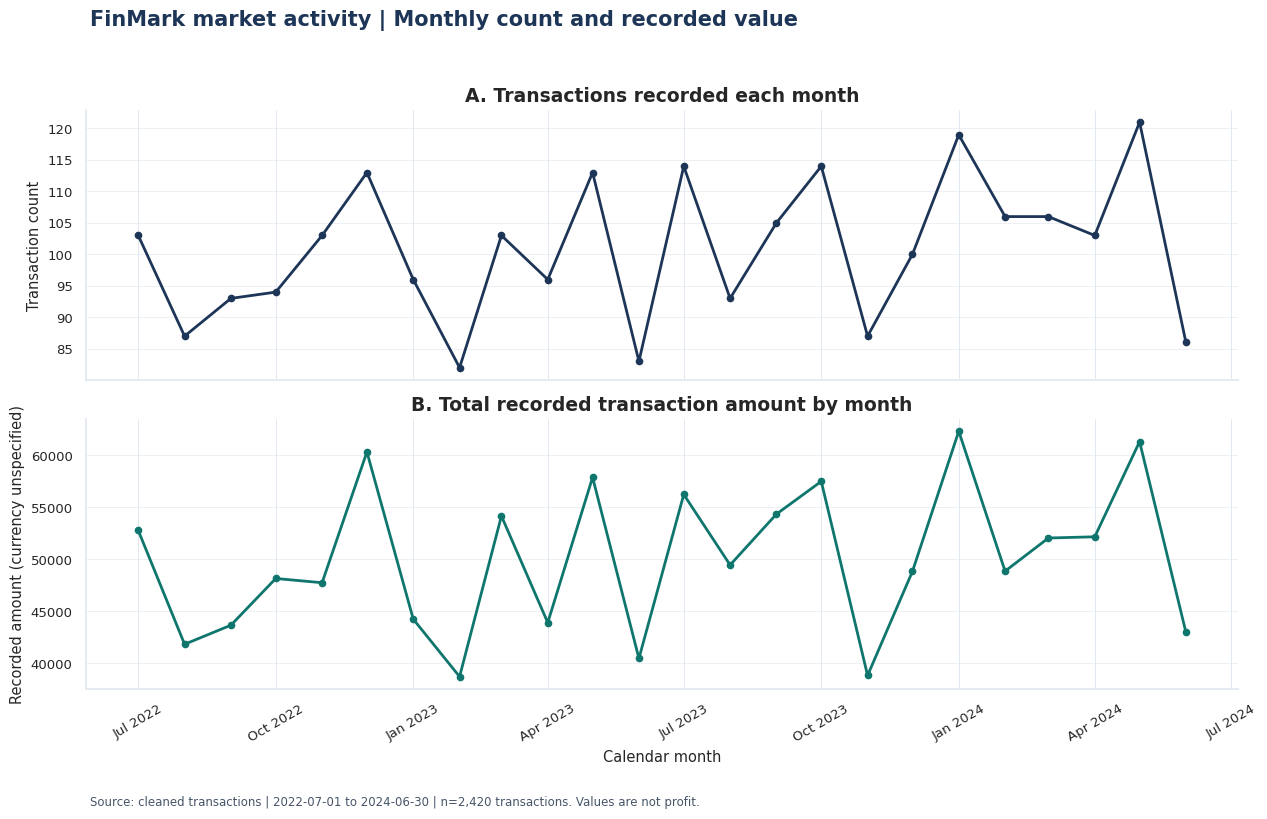

Months: 24; monthly count 82–121
Highest count: May 2024 (121); lowest: February 2023 (82)
Monthly transaction sum (all amounts): 1,198,500.13


,month,transaction_count,total_value
0,2022-07,103,52762.39
1,2022-08,87,41813.81
2,2022-09,93,43649.69
3,2022-10,94,48143.62
4,2022-11,103,47736.54
5,2022-12,113,60322.10
6,2023-01,96,44232.02
7,2023-02,82,38698.27
8,2023-03,103,54157.23
9,2023-04,96,43895.54


In [5]:
# @title
## @title
# Figure 1 | Full transaction history (not the shortened social comparison window)
month_values = transactions.transaction_date.dt.to_period('M')
monthly_tx = (transactions.assign(month=month_values)
              .groupby('month').agg(transaction_count=('transaction_id','size'),
                                    total_value=('amount','sum'))
              .sort_index())
expected_months = pd.period_range(month_values.min(),month_values.max(),freq='M')
if not monthly_tx.index.equals(expected_months):
    raise ValueError('Unexpected missing monthly groups: investigate zero-activity months')
monthly_tx = monthly_tx.reset_index()
monthly_tx['month'] = monthly_tx['month'].dt.to_timestamp()
assert monthly_tx.transaction_count.sum() == len(transactions)
assert np.isclose(monthly_tx.total_value.sum(),transactions.amount.sum())

fig, axes = plt.subplots(2,1,figsize=(12.8,8.2),sharex=True)
for ax,field,color,title,ylabel in [
    (axes[0],'transaction_count',NAVY,'A. Transactions recorded each month','Transaction count'),
    (axes[1],'total_value',TEAL,'B. Total recorded transaction amount by month','Recorded amount (currency unspecified)')
]:
    ax.plot(monthly_tx.month, monthly_tx[field], marker='o',markersize=4.5,linewidth=2,color=color)
    ax.set(title=title,ylabel=ylabel)
    polish(ax)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[1].set_xlabel('Calendar month')
axes[1].tick_params(axis='x',rotation=30)
fig.suptitle('FinMark market activity | Monthly count and recorded value',x=.075,ha='left',fontsize=15,weight='bold',color=NAVY)
figure_note(fig,f'Source: cleaned transactions | {transaction_period[0]} to {transaction_period[1]} | n={len(transactions):,} transactions. Values are not profit.')
fig.tight_layout(rect=[0,.04,1,.95]);save_chart('01_monthly_counts_and_recorded_amounts.png'); plt.show()
peak = monthly_tx.loc[monthly_tx.transaction_count.idxmax()]
low = monthly_tx.loc[monthly_tx.transaction_count.idxmin()]
print(f'Months: {len(monthly_tx)}; monthly count {monthly_tx.transaction_count.min()}–{monthly_tx.transaction_count.max()}')
print(f'Highest count: {peak.month:%B %Y} ({peak.transaction_count}); lowest: {low.month:%B %Y} ({low.transaction_count})')
print('Monthly transaction sum (all amounts):',f'{transactions.amount.sum():,.2f}')
display(monthly_tx.assign(month=monthly_tx.month.dt.strftime('%Y-%m')).round(2))

**Interpretation:** The monthly counts range from 82 to 121. Peaks and dips warrant monitoring, but their causes are not established. Monitor **both** purchase counts and recorded amounts, and investigate unusual months only with verified operational context.

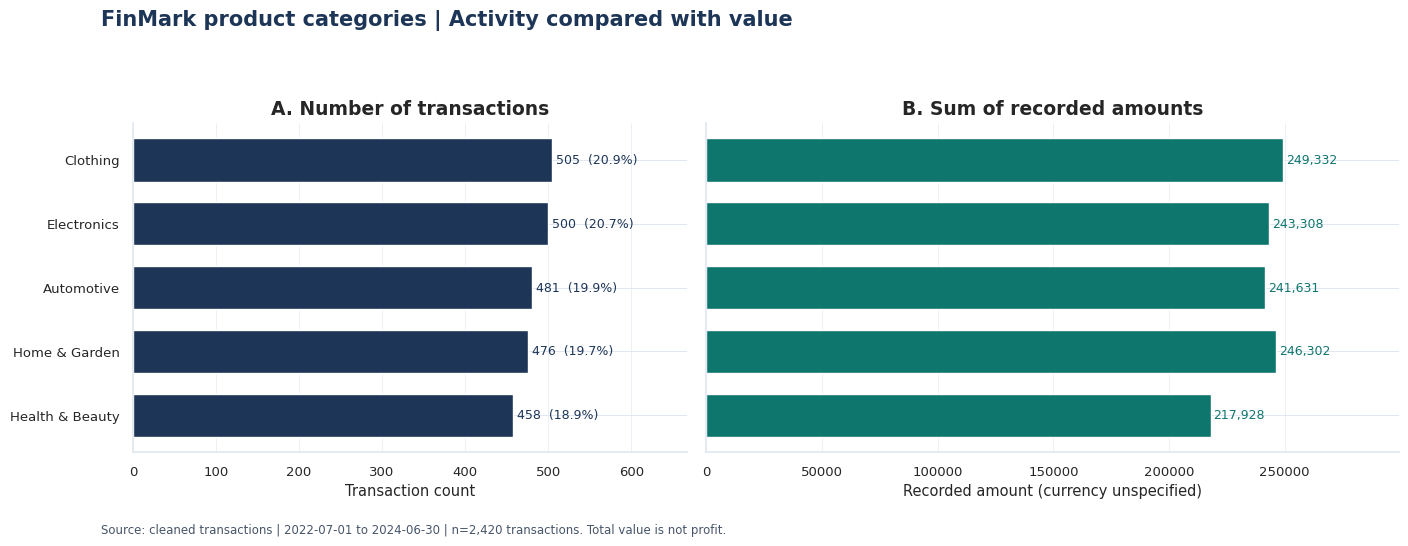

,transaction_count,total_value,mean_amount,median_amount,transaction_share_pct
product_category,,,,,
Clothing,505,249331.84,493.73,496.26,20.87
Electronics,500,243308.08,486.62,505.80,20.66
Automotive,481,241630.54,502.35,517.45,19.88
Home & Garden,476,246301.50,517.44,517.32,19.67
Health & Beauty,458,217928.17,475.83,463.32,18.93


Category count share range: 18.93%–20.87%


In [6]:
# @title
## @title
# Figure 2 | Category activity and value, aligned category ordering
category_summary = (transactions.groupby('product_category').agg(
    transaction_count=('transaction_id','size'),
    total_value=('amount','sum'),
    mean_amount=('amount','mean'),
    median_amount=('amount','median'),
).sort_values('transaction_count',ascending=True))
category_summary['transaction_share_pct'] = 100*category_summary.transaction_count/len(transactions)
assert category_summary.transaction_count.sum() == len(transactions)

names = category_summary.index.tolist()
y = np.arange(len(names))
fig,axes=plt.subplots(1,2,figsize=(14.2,5.4),sharey=True,gridspec_kw={'width_ratios':[1,1.25]})
axes[0].barh(y,category_summary.transaction_count,color=NAVY,height=.68)
axes[1].barh(y,category_summary.total_value,color=TEAL,height=.68)
axes[0].set_yticks(y,labels=names)
axes[0].set(title='A. Number of transactions',xlabel='Transaction count')
axes[1].set(title='B. Sum of recorded amounts',xlabel='Recorded amount (currency unspecified)')
for i,(_,v) in enumerate(category_summary.iterrows()):
    axes[0].text(v.transaction_count+4,i,f'{int(v.transaction_count):,}  ({v.transaction_share_pct:.1f}%)',va='center',fontsize=9,color=NAVY)
    axes[1].text(v.total_value+1300,i,f'{v.total_value:,.0f}',va='center',fontsize=9,color=TEAL)
axes[0].set_xlim(0,category_summary.transaction_count.max()*1.32)
axes[1].set_xlim(0,category_summary.total_value.max()*1.20)
for ax in axes:polish(ax,ygrid=True)
fig.suptitle('FinMark product categories | Activity compared with value',x=.075,ha='left',fontsize=15,weight='bold',color=NAVY)
figure_note(fig,f'Source: cleaned transactions | {transaction_period[0]} to {transaction_period[1]} | n={len(transactions):,} transactions. Total value is not profit.')
fig.tight_layout(rect=[0,.045,1,.91]);save_chart('02_category_counts_and_values.png'); plt.show()
display(category_summary.sort_values('transaction_count',ascending=False).round(2))
print('Category count share range:',f'{category_summary.transaction_share_pct.min():.2f}%–{category_summary.transaction_share_pct.max():.2f}%')

**Interpretation:** Counts across the five categories are close; total recorded amounts differ. Without validated costs/returns and margins, avoid inventory or profitability conclusions from either count or gross recorded amount alone.

## 4. Transaction amount distribution (Milestone 2 supporting analysis)
**Question:** How wide is the spread of recorded transaction amounts, and how should unusual zeros be treated?
**Method:** Transaction-level histogram, center/spread and 1.5×IQR inspection. Keep 54 zero-valued transactions while provenance remains unresolved.

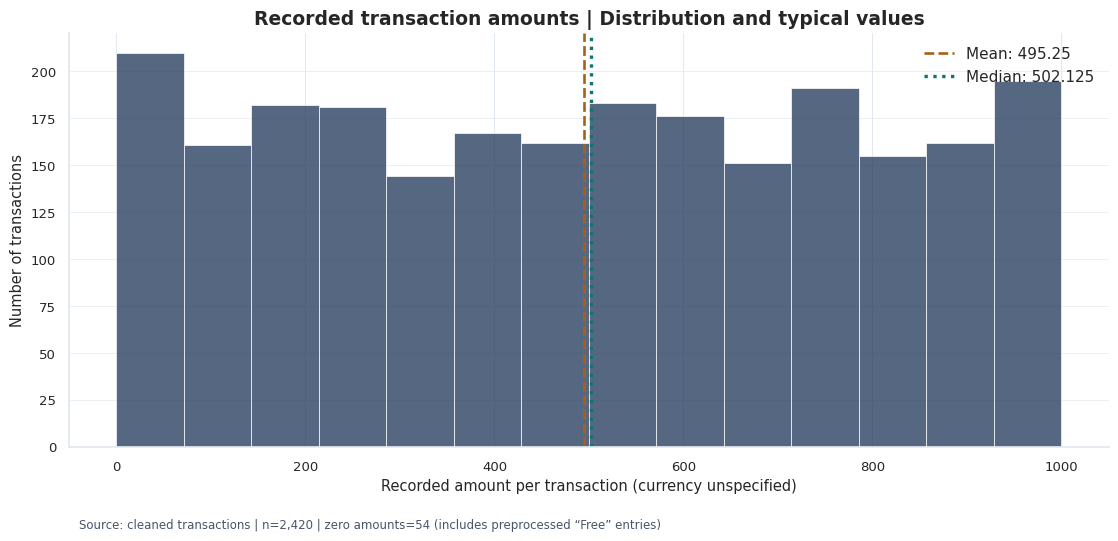

,measure,value
0,Transactions,2420.000
1,Mean,495.248
2,Median,502.125
3,SD,295.711
4,Min,0.000
5,Q1,234.278
6,Q3,747.752
7,IQR,513.475
8,Max,999.860
9,Zero amounts,54.000


IQR diagnostic bounds: -535.94 to 1517.97; observations flagged: 0


In [7]:
# @title
## @title
# Figure 3 | Transaction amount histogram + validated numerical summary
amount = transactions.amount.dropna()
q1,q3 = amount.quantile([.25,.75]);iqr=q3-q1
low_limit=q1-1.5*iqr;high_limit=q3+1.5*iqr
outlier_mask=(amount<low_limit)|(amount>high_limit)
fig,ax=plt.subplots(figsize=(11.3,5.4))
sns.histplot(amount,bins='fd',color=NAVY,edgecolor='white',linewidth=.5,ax=ax)
ax.axvline(amount.mean(),color=AMBER,linestyle='--',linewidth=1.9,label=f'Mean: {amount.mean():,.2f}')
ax.axvline(amount.median(),color=TEAL,linestyle=':',linewidth=2.4,label=f'Median: {amount.median():,.3f}')
ax.set(title='Recorded transaction amounts | Distribution and typical values',
       xlabel='Recorded amount per transaction (currency unspecified)',ylabel='Number of transactions')
ax.legend(frameon=False,loc='upper right');polish(ax)
figure_note(fig,f'Source: cleaned transactions | n={len(amount):,} | zero amounts={int(amount.eq(0).sum())} (includes preprocessed “Free” entries)')
fig.tight_layout(rect=[0,.045,1,1]);save_chart('03_transaction_amount_distribution.png'); plt.show()
amount_stats=pd.DataFrame({'measure':['Transactions','Mean','Median','SD','Min','Q1','Q3','IQR','Max','Zero amounts','IQR-flagged values'],
                           'value':[len(amount),amount.mean(),amount.median(),amount.std(),amount.min(),q1,q3,iqr,amount.max(),amount.eq(0).sum(),outlier_mask.sum()]})
display(amount_stats.round(3))
print(f'IQR diagnostic bounds: {low_limit:.2f} to {high_limit:.2f}; observations flagged: {outlier_mask.sum()}')

## 5. Customer purchasing habits (Terminal Slide 6, added analysis)
This is an **additional customer-level descriptive analysis developed for the Terminal Assessment**, not a finding attributed to the earlier Milestone 2 notebook. It strengthens the motivation for a *possible* clustering pilot.

**Three questions:** How many times did each buyer purchase? How much did each spend in the recorded window? How many distinct product categories did each buyer purchase?

**Method:** Aggregate the full transaction dataset by `customer_id`. Each buyer contributes one row. Spending is total **recorded amount**, without a confirmed currency. A buyer with one recorded purchase is not necessarily a lifetime first-time or inactive customer.

In [8]:
# @title
# One customer, one row: 24-month purchasing profile (no demographics/social join needed).
buyer_profile = (transactions.groupby('customer_id', as_index=False)
    .agg(purchase_count=('transaction_id', 'size'),
         total_recorded_amount=('amount', 'sum'),
         average_recorded_amount=('amount', 'mean'),
         distinct_categories=('product_category', 'nunique')))
assert buyer_profile.customer_id.is_unique
assert len(buyer_profile) == 1642
assert int(buyer_profile.purchase_count.sum()) == len(transactions)
assert np.isclose(buyer_profile.total_recorded_amount.sum(), transactions.amount.sum())
frequency_bins = pd.cut(buyer_profile.purchase_count, bins=[0,1,2,3,np.inf], labels=['1','2','3','4+'])
frequency_counts = frequency_bins.value_counts().reindex(['1','2','3','4+'],fill_value=0)
category_breadth = buyer_profile.distinct_categories.eq(1)
profile_metrics = {
    'buyers': len(buyer_profile),
    'one_purchase_buyers': int((buyer_profile.purchase_count == 1).sum()),
    'one_purchase_pct': 100 * buyer_profile.purchase_count.eq(1).mean(),
    'median_total_amount': float(buyer_profile.total_recorded_amount.median()),
    'mean_total_amount': float(buyer_profile.total_recorded_amount.mean()),
    'one_category_buyers': int(category_breadth.sum()),
    'one_category_pct': 100 * category_breadth.mean(),
}
display(pd.DataFrame([profile_metrics]).T.rename(columns={0:'Recomputed result'}))
assert list(frequency_counts) == [1060,422,132,28]
assert profile_metrics['one_category_buyers']==1143
assert np.isclose(profile_metrics['median_total_amount'],672.04,atol=.01)
assert np.isclose(profile_metrics['mean_total_amount'],729.90,atol=.01)

,Recomputed result
buyers,1642.000000
one_purchase_buyers,1060.000000
one_purchase_pct,64.555420
median_total_amount,672.035000
mean_total_amount,729.902637
one_category_buyers,1143.000000
one_category_pct,69.610231


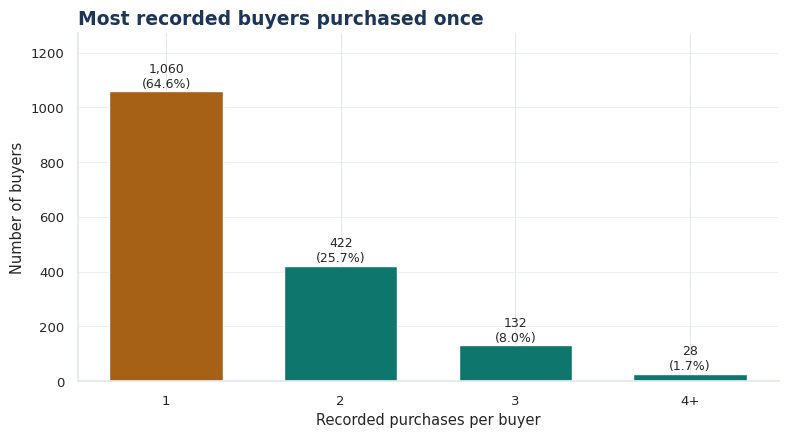

In [9]:
# @title
# Terminal Slide 6A: Recorded purchase frequency per buyer.
fig,ax=plt.subplots(figsize=(8,4.5))
vals=frequency_counts.to_numpy()
colors=[AMBER,TEAL,TEAL,TEAL]
bars=ax.bar(frequency_counts.index, vals, color=colors, width=.65)
for bar,count in zip(bars,vals):
    ax.text(bar.get_x()+bar.get_width()/2,count+14,f'{count:,}\n({100*count/len(buyer_profile):.1f}%)',ha='center',fontsize=9)
ax.set_ylim(0,max(vals)*1.2);ax.set_ylabel('Number of buyers');ax.set_xlabel('Recorded purchases per buyer')
ax.set_title('Most recorded buyers purchased once',loc='left',color=NAVY)
polish(ax);fig.tight_layout();save_chart('04_customer_purchase_frequency.png');plt.show()

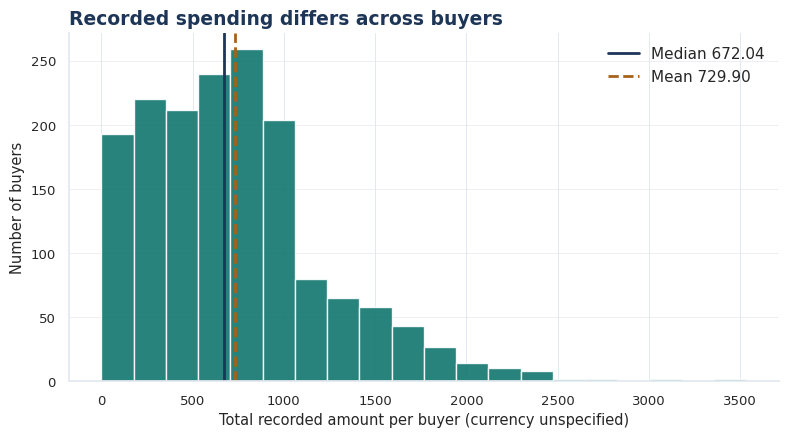

In [10]:
# @title
# Terminal Slide 6B: Customer-level total recorded amount histogram.
fig,ax=plt.subplots(figsize=(8,4.5))
spend=buyer_profile.total_recorded_amount
ax.hist(spend,bins=20,color=TEAL,edgecolor='white',alpha=.9)
ax.axvline(spend.median(),color=NAVY,linewidth=2,label=f'Median {spend.median():,.2f}')
ax.axvline(spend.mean(),color=AMBER,linewidth=2,linestyle='--',label=f'Mean {spend.mean():,.2f}')
ax.legend(frameon=False)
ax.set_xlabel('Total recorded amount per buyer (currency unspecified)')
ax.set_ylabel('Number of buyers')
ax.set_title('Recorded spending differs across buyers',loc='left',color=NAVY)
polish(ax);fig.tight_layout();save_chart('05_customer_total_amount_distribution.png');plt.show()

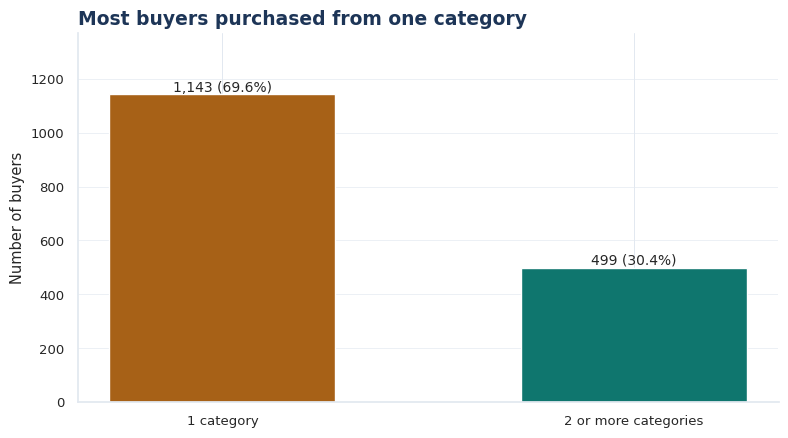

In [11]:
# @title
# Terminal Slide 6C: Number of different categories purchased.
breadth_counts=pd.Series({'1 category':int(category_breadth.sum()),
                         '2 or more categories':int((~category_breadth).sum())})
fig,ax=plt.subplots(figsize=(8,4.5))
bars=ax.bar(breadth_counts.index,breadth_counts.values,color=[AMBER,TEAL],width=.55)
for b,count in zip(bars,breadth_counts.values):
    ax.text(b.get_x()+b.get_width()/2,count+12,f'{count:,} ({count/len(buyer_profile):.1%})',ha='center',fontsize=10)
ax.set_ylim(0,max(breadth_counts.values)*1.2);ax.set_ylabel('Number of buyers')
ax.set_title('Most buyers purchased from one category',loc='left',color=NAVY)
polish(ax);fig.tight_layout();save_chart('06_customer_category_breadth.png');plt.show()

**Interpretation:** 1,060 of 1,642 buyers (64.6%) have exactly one recorded purchase; the median customer total is 672.04 and mean is 729.90; 1,143 (69.6%) purchased from only one category. **Business implication:** these dimensions could be examined together in a future segmentation feasibility study, but these descriptive distributions **do not demonstrate distinct clusters**. The 1,642 transaction-only buyers can be considered before any demographic or social joins; inclusion of additional sources reduces the eligible population.

## 6. Demographic category participation (Terminal Slide 7)
**Question:** Is recorded gender associated with whether a buyer purchased from a specific category?

**Method:** 1,306 matched profile+transaction customers; a binary purchased/not-purchased outcome for each category, corrected across five tests. We report effect size as well as the significance test. **Do not treat this observational relationship as evidence for gender-only targeting.**

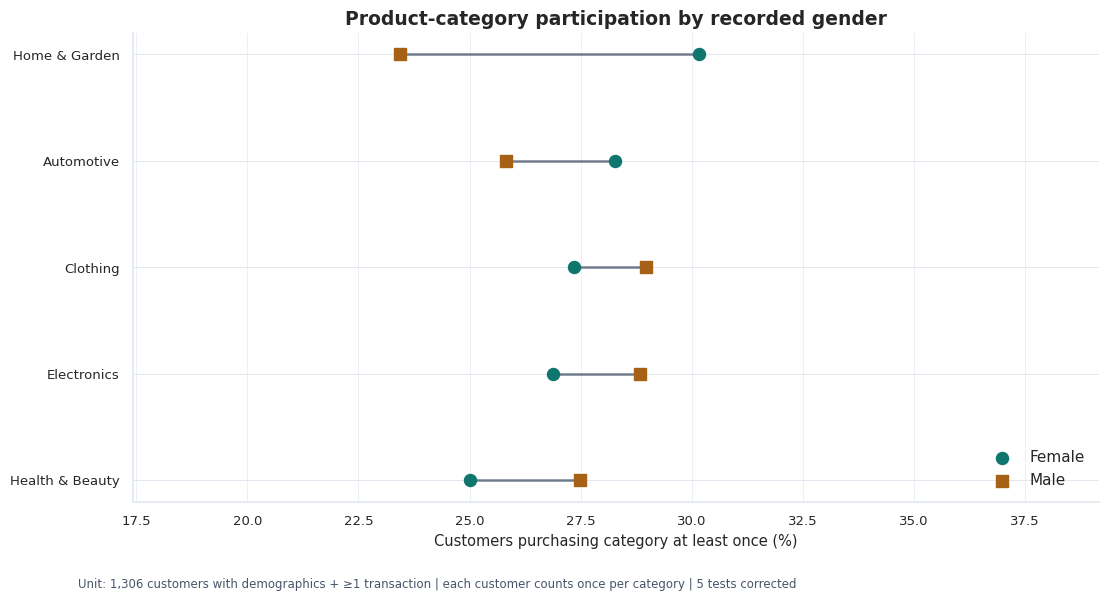

,Category,Female %,Male %,Gap (pp),chi2,p,Bonferroni p,Cramers V,Min expected,Adjusted p < 0.05
0,Health & Beauty,25.0000,27.4775,-2.4775,0.9104,0.3400,1.0000,0.0264,168.0858,False
1,Electronics,26.8750,28.8288,-1.9538,0.5264,0.4681,1.0000,0.0201,178.3767,False
2,Clothing,27.3438,28.9790,-1.6352,0.3542,0.5517,1.0000,0.0165,180.3369,False
3,Automotive,28.2813,25.8258,2.4554,0.8771,0.3490,1.0000,0.0259,172.9862,False
4,Home & Garden,30.1562,23.4234,6.7328,7.2154,0.0072,0.0361,0.0743,171.0260,True


Significant categories after Bonferroni: Home & Garden


In [12]:
# @title
## @title
# Figure 4 | Matched-customer participation; inferential evidence with multiplicity control
observed_gender=set(category_population.gender.dropna().unique())
if observed_gender != {'Female','Male'}:
    raise ValueError(f'Gender categories differ from reviewed version: {sorted(observed_gender)}')

results=[]
for category in sorted(transactions.product_category.dropna().unique()):
    buyers=set(transactions.loc[transactions.product_category.eq(category),'customer_id'])
    frame=category_population.assign(purchased=category_population.customer_id.isin(buyers))
    tab=pd.crosstab(frame.gender,frame.purchased).reindex(
        index=['Female','Male'],columns=[False,True],fill_value=0)
    chi2,pvalue,dof,expected=stats.chi2_contingency(tab)
    min_expected=float(expected.min())
    if min_expected < 5:
        raise ValueError(f'Chi-square expected-count condition not met: {category} ({min_expected:.2f})')
    rates=frame.groupby('gender').purchased.mean()*100
    n=tab.to_numpy().sum()
    v=np.sqrt(chi2/(n*min(tab.shape[0]-1,tab.shape[1]-1)))
    results.append({'Category':category,'Female %':rates['Female'],'Male %':rates['Male'],
                    'Gap (pp)':rates['Female']-rates['Male'],'chi2':chi2,'p':pvalue,
                    'Cramers V':v,'Min expected':min_expected})
gender_results=pd.DataFrame(results)
gender_results['Bonferroni p']=np.minimum(gender_results.p*len(gender_results),1)
gender_results['Adjusted p < 0.05']=gender_results['Bonferroni p']<.05
gender_results=gender_results.sort_values('Female %',ascending=True).reset_index(drop=True)

fig,ax=plt.subplots(figsize=(11.2,6))
y=np.arange(len(gender_results))
for i,row in gender_results.iterrows():
    ax.plot([row['Female %'],row['Male %']],[i,i],color=SLATE,linewidth=1.8,alpha=.75,zorder=2)
ax.scatter(gender_results['Female %'],y,s=75,color=TEAL,label='Female',zorder=3,marker='o')
ax.scatter(gender_results['Male %'],y,s=75,color=AMBER,label='Male',zorder=3,marker='s')
ax.set_yticks(y,labels=gender_results['Category'])
ax.set(xlabel='Customers purchasing category at least once (%)',
       title='Product-category participation by recorded gender')
ax.legend(frameon=False,loc='lower right')
ax.set_xlim(max(0,gender_results[['Female %','Male %']].min().min()-6),
             gender_results[['Female %','Male %']].max().max()+9)
polish(ax,ygrid=True)
figure_note(fig,f'Unit: {len(category_population):,} customers with demographics + ≥1 transaction | each customer counts once per category | 5 tests corrected')
fig.tight_layout(rect=[0,.05,1,1]);save_chart('07_gender_category_participation.png'); plt.show()
display(gender_results[['Category','Female %','Male %','Gap (pp)','chi2','p','Bonferroni p','Cramers V','Min expected','Adjusted p < 0.05']].round(4))
print('Significant categories after Bonferroni:',
      ', '.join(gender_results.loc[gender_results['Adjusted p < 0.05'],'Category']) or 'None')

**Interpretation:** The Home & Garden comparison is 30.16% among recorded Female buyers versus 23.42% among recorded Male buyers; adjusted p=0.0361, but Cramér's V=0.0743 indicates a very small association. This does not justify a demographic intervention.

## 7. Recorded social sentiment (Milestone 2 support)
**Question:** How does the composition of recorded sentiments vary by month?

**Method:** Display event-level monthly percentages. The chart is a monitoring tool, not a verified change in customer satisfaction. Repeated social events from one customer must not be mistaken for independent customers.

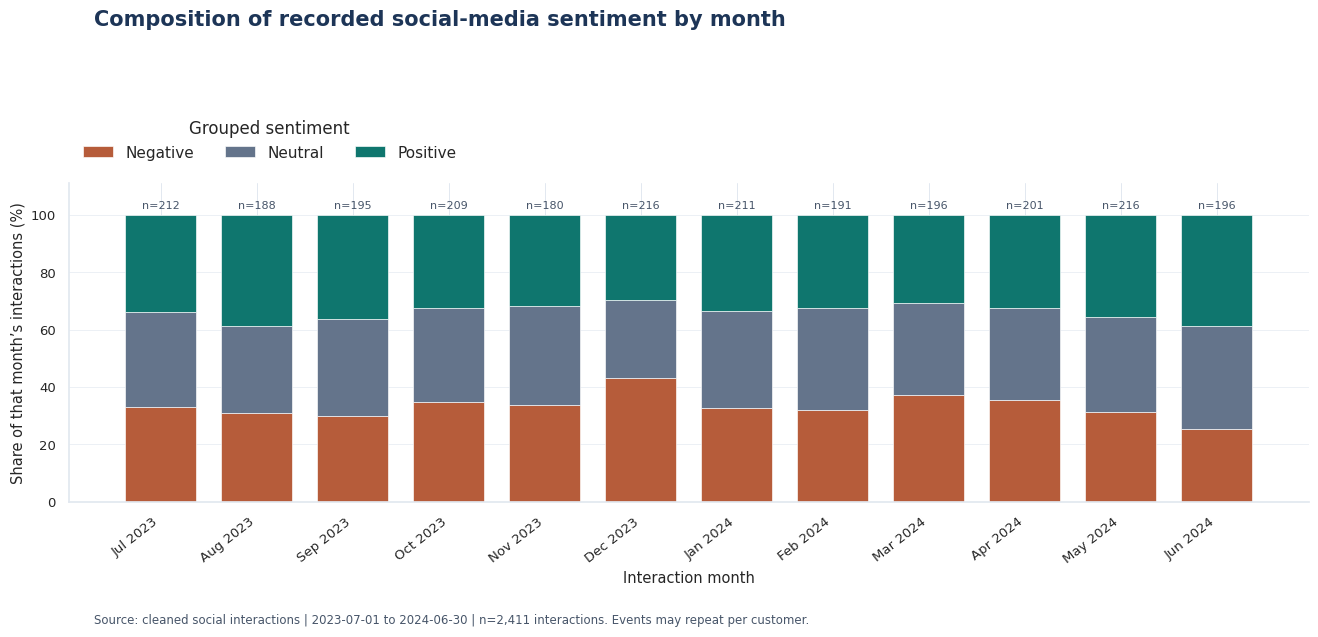

sentiment_group,Interactions,Negative,Neutral,Positive
month,,,,
2023-07,212,33.0,33.0,34.0
2023-08,188,30.9,30.3,38.8
2023-09,195,29.7,33.8,36.4
2023-10,209,34.9,32.5,32.5
2023-11,180,33.9,34.4,31.7
2023-12,216,43.1,27.3,29.6
2024-01,211,32.7,33.6,33.6
2024-02,191,31.9,35.6,32.5
2024-03,196,37.2,32.1,30.6


Original five sentiment categories:


,Interactions
Sentiment,
Neutral,790
Positive,790
Negative,780
Very Positive,26
Very Negative,25


Duplicate customer-month interaction occurrences: 95


In [13]:
# @title
## @title
# Figure 5 | 100% stacked monthly sentiment with explicit event counts
sentiment_map = {
    'Very Negative':'Negative','Negative':'Negative',
    'Neutral':'Neutral','Positive':'Positive','Very Positive':'Positive'
}
if not social.sentiment.isin(sentiment_map).all():
    raise ValueError('Unrecognized sentiment label(s): review source labels before grouping')
social_plot=social.assign(
    month=social.interaction_date.dt.to_period('M'),
    sentiment_group=social.sentiment.map(sentiment_map)
)
monthly_sentiment_counts=pd.crosstab(social_plot.month,social_plot.sentiment_group)
monthly_sentiment_counts=monthly_sentiment_counts.reindex(columns=['Negative','Neutral','Positive'],fill_value=0)
monthly_social_n=monthly_sentiment_counts.sum(axis=1)
monthly_sentiment_pct=monthly_sentiment_counts.div(monthly_social_n,axis=0)*100
assert np.allclose(monthly_sentiment_pct.sum(axis=1),100)

fig,ax=plt.subplots(figsize=(13.3,6.3))
indices=np.arange(len(monthly_sentiment_pct)); bottom=np.zeros(len(indices))
for sentiment in ['Negative','Neutral','Positive']:
    values=monthly_sentiment_pct[sentiment].to_numpy()
    ax.bar(indices,values,bottom=bottom,color=SENTIMENT_COLORS[sentiment],
           label=sentiment,width=.74,edgecolor='white',linewidth=.45)
    bottom += values
for i,n in enumerate(monthly_social_n):
    ax.text(i,101.5,f'n={n}',ha='center',va='bottom',fontsize=8,color=SLATE)
ax.set_ylim(0,111)
ax.set_xticks(indices,labels=[p.strftime('%b %Y') for p in monthly_sentiment_pct.index],rotation=38,ha='right')
ax.set(ylabel='Share of that month’s interactions (%)',xlabel='Interaction month')
fig.suptitle('Composition of recorded social-media sentiment by month',x=.075,ha='left',y=.985,fontsize=15,weight='bold',color=NAVY)
ax.legend(title='Grouped sentiment',frameon=False,ncol=3,loc='lower left',bbox_to_anchor=(0,1.03))
polish(ax)
figure_note(fig,f'Source: cleaned social interactions | {social.interaction_date.min().date()} to {social.interaction_date.max().date()} | n={len(social):,} interactions. Events may repeat per customer.')
fig.tight_layout(rect=[0,.045,1,.91]);save_chart('08_monthly_sentiment_composition.png'); plt.show()
monthly_sentiment_table=monthly_sentiment_pct.copy()
monthly_sentiment_table.insert(0,'Interactions',monthly_social_n)
monthly_sentiment_table.index=monthly_sentiment_table.index.astype(str)
display(monthly_sentiment_table.round(1))
print('Original five sentiment categories:')
display(social.sentiment.value_counts().rename_axis('Sentiment').to_frame('Interactions'))
print('Duplicate customer-month interaction occurrences:',int(social_plot.duplicated(['customer_id','month']).sum()))

## 8. Social interaction frequency and purchases (Terminal Slide 7)
**Question:** Do people who interact more on social media also record more purchasing activity?

**Method:** Compare the same July 2023–June 2024 dates, aggregate to one row per customer, then compute Pearson and Spearman correlations, uncertainty and corrected p-values. Report **unadjusted p-values** separately from **three-test-adjusted p-values**. Use the adjusted results when interpreting statistical significance.

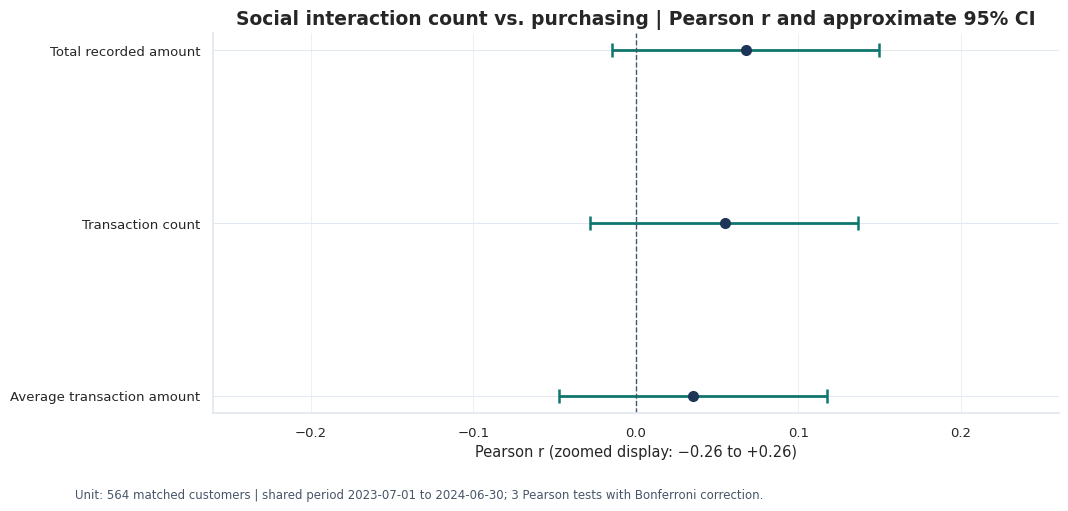

,Outcome,Pearson r,Pearson p,CI lower,CI upper,Spearman rho,Spearman p,Bonferroni p,Adjusted p < 0.05
0,Total recorded amount,0.0678,0.1075,-0.0148,0.1496,0.0566,0.1798,0.3226,False
1,Transaction count,0.0547,0.1949,-0.0280,0.1366,0.0603,0.1529,0.5847,False
2,Average transaction amount,0.0354,0.4011,-0.0473,0.1176,0.0291,0.4900,1.0000,False


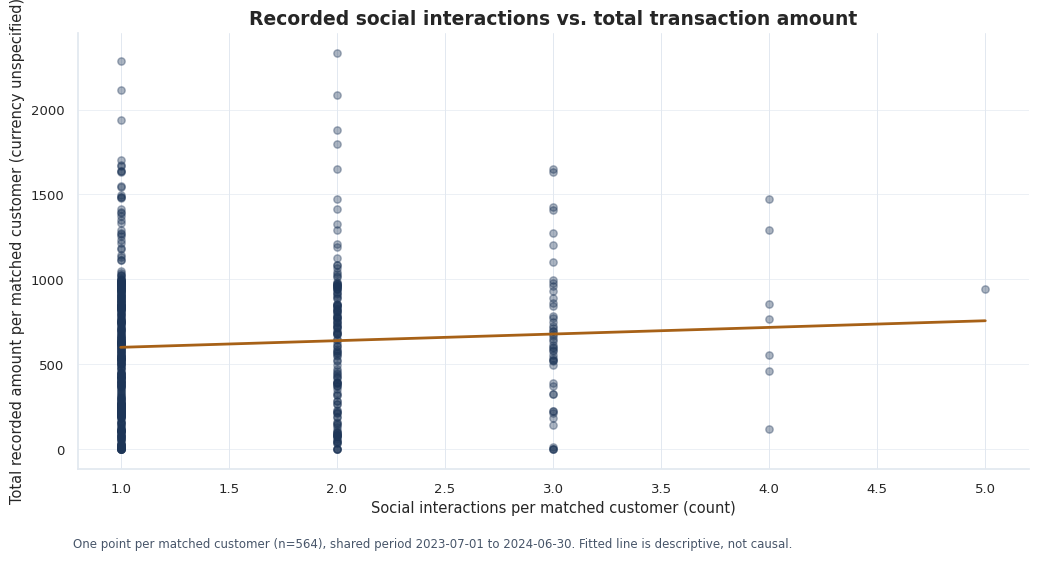

Matched customer count: 564
Bonferroni-adjusted significant Pearson outcomes: []


In [14]:
# @title
## @title
# Figures 6–7 | Customer-level correlations with uncertainty + one raw-data scatter
from math import atanh,tanh,sqrt

if len(matched)<4:
    raise ValueError('Need at least 4 matched customers for Fisher-z CIs')
if matched.interaction_count.nunique()<2:
    raise ValueError('Insufficient variation in interaction counts for correlation')

relationship_rows=[]
for label,column in [('Total recorded amount','total_spend'),
                     ('Transaction count','transaction_count'),
                     ('Average transaction amount','average_transaction_amount')]:
    if matched[column].nunique()<2:
        raise ValueError(f'Insufficient outcome variation in {column}')
    r,p=stats.pearsonr(matched.interaction_count,matched[column])
    rho,p_rank=stats.spearmanr(matched.interaction_count,matched[column])
    z=atanh(float(np.clip(r,-.999999999,.999999999)))
    width=1.96/sqrt(len(matched)-3)
    ci_low,ci_high=tanh(z-width),tanh(z+width)
    relationship_rows.append({'Outcome':label,'Pearson r':r,'Pearson p':p,
                              'CI lower':ci_low,'CI upper':ci_high,
                              'Spearman rho':rho,'Spearman p':p_rank})
relationship=pd.DataFrame(relationship_rows)
relationship['Bonferroni p']=np.minimum(1,relationship['Pearson p']*len(relationship))
relationship['Adjusted p < 0.05']=relationship['Bonferroni p']<.05

fig,ax=plt.subplots(figsize=(10.8,5.1))
y=np.arange(len(relationship))
x=relationship['Pearson r'].to_numpy()
err=np.vstack([x-relationship['CI lower'].to_numpy(),relationship['CI upper'].to_numpy()-x])
ax.errorbar(x,y,xerr=err,fmt='o',color=NAVY,ecolor=TEAL,capthick=1.8,capsize=5,
            elinewidth=2,markersize=7)
ax.axvline(0,color=SLATE,linewidth=1,linestyle='--')
ax.set_yticks(y,labels=relationship['Outcome'])
ax.invert_yaxis()
ax.set_xlim(-.26,.26)
ax.set(xlabel='Pearson r (zoomed display: −0.26 to +0.26)',
       title='Social interaction count vs. purchasing | Pearson r and approximate 95% CI')
polish(ax,ygrid=True)
figure_note(fig,f'Unit: {len(matched):,} matched customers | shared period {common_start.date()} to {common_end.date()}; 3 Pearson tests with Bonferroni correction.')
fig.tight_layout(rect=[0,.055,1,1]);save_chart('09_social_correlations_with_intervals.png'); plt.show()
display(relationship.round(4))

fig,ax=plt.subplots(figsize=(10.5,5.6))
sns.regplot(data=matched,x='interaction_count',y='total_spend',ci=None,
            scatter_kws={'color':NAVY,'alpha':.37,'s':28},
            line_kws={'color':AMBER,'linewidth':2},ax=ax)
ax.set(title='Recorded social interactions vs. total transaction amount',
       xlabel='Social interactions per matched customer (count)',
       ylabel='Total recorded amount per matched customer (currency unspecified)')
polish(ax)
figure_note(fig,f'One point per matched customer (n={len(matched):,}), shared period {common_start.date()} to {common_end.date()}. Fitted line is descriptive, not causal.')
fig.tight_layout(rect=[0,.04,1,1]);save_chart('10_social_interactions_vs_total_amount.png'); plt.show()
print('Matched customer count:',len(matched))
print('Bonferroni-adjusted significant Pearson outcomes:',
      relationship.loc[relationship['Adjusted p < 0.05'],'Outcome'].tolist())

**Interpretation:** The three reported correlation coefficients are positive but very weak (|r| below 0.07), with no statistically supported effect under the selected corrected tests. Raw interaction count alone is insufficient for customer-value ranking. The finding does **not** prove that social campaigns have no effects.

## 9. Simple forecasting baselines (Terminal Slide 8)
**Question:** Are simple past-month estimates useful starting points for a possible future forecasting study?

**Method:** Only monthly transaction counts, with time-ordered one-step-ahead estimates for January–June 2024. Compare a previous-month count against a prior-three-month mean. These are **baselines, not trained ML models**; six holdout months are not adequate for production validation.

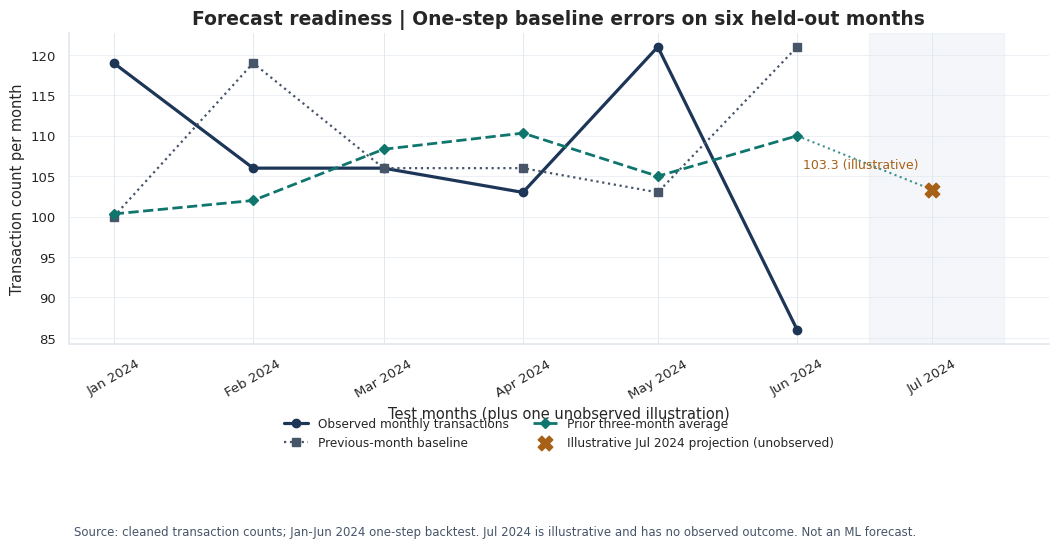

Forecast baseline evaluation, January-June 2024 (only six one-step test observations):


,Baseline,Mean Absolute Error (transactions/month),Root Mean Squared Error (transactions/month),Test months
0,Previous month,14.667,18.655,6
1,Prior 3-month mean,12.056,14.466,6


Read the results: MAE is the average number of transactions missed; RMSE places extra weight on larger misses. Lower is better.


,month,Observed,Previous month,Prior 3-month mean
0,2024-01,119.0,100.0,100.33
1,2024-02,106.0,119.0,102.00
2,2024-03,106.0,106.0,108.33
3,2024-04,103.0,106.0,110.33
4,2024-05,121.0,103.0,105.00
5,2024-06,86.0,121.0,110.00


Illustrative July 2024 next-month count using 3-month average: 103.333 (~103 transactions).
No verified July 2024 result, trained ML model, formal prediction interval, or prospective forecast claim.


In [15]:
# @title
## @title
# Forecast-readiness diagnostic | time-ordered one-step baselines, not trained ML
# Uses ONLY recorded monthly transaction counts; both baselines lag actual data.
series = monthly_tx.set_index('month')['transaction_count'].astype(float).sort_index()
if len(series) != 24 or not series.index.is_monotonic_increasing:
    raise ValueError('Forecast demonstration requires 24 complete chronological months')
expected = pd.period_range(series.index.min().to_period('M'),
                           series.index.max().to_period('M'), freq='M')
assert series.index.to_period('M').equals(expected), 'Missing calendar month(s)'

forecast_history_months = 18
forecast_test_months = 6
n_obs = len(series)
if n_obs != forecast_history_months + forecast_test_months:
    raise ValueError('Expected 18 initial months and six evaluation months')
monthly_counts = series.to_numpy(dtype=float)
backtest_rows = []
for t in range(forecast_history_months, n_obs):
    # Strictly use months 0,...,t-1 to forecast the observed month t.
    backtest_rows.append({
        'month': series.index[t],
        'Observed': float(monthly_counts[t]),
        'Previous month': float(monthly_counts[t-1]),
        'Prior 3-month mean': float(monthly_counts[t-3:t].mean()),
    })
forecast_backtest = pd.DataFrame(backtest_rows)
assert len(forecast_backtest) == 6
assert forecast_backtest.month.min() == pd.Timestamp('2024-01-01')
assert forecast_backtest.month.max() == pd.Timestamp('2024-06-01')

forecast_metrics = pd.DataFrame([
    {
        'Baseline': name,
        'MAE (transactions/month)': float(np.abs(forecast_backtest['Observed'] - forecast_backtest[name]).mean()),
        'RMSE (transactions/month)': float(np.sqrt(np.square(forecast_backtest['Observed']-forecast_backtest[name]).mean())),
        'Test months': len(forecast_backtest)
    }
    for name in ['Previous month','Prior 3-month mean']
])
# Illustration: project one additional month beyond available series, with no observed truth.
illustrative_month = series.index.max() + pd.offsets.MonthBegin(1)
illustrative_point = float(monthly_counts[-3:].mean())
assert illustrative_month == pd.Timestamp('2024-07-01')

fig, ax = plt.subplots(figsize=(10.7,5.7))
ax.plot(forecast_backtest.month, forecast_backtest['Observed'],
        color=NAVY, marker='o', markersize=6, linewidth=2.3, label='Observed monthly transactions')
ax.plot(forecast_backtest.month, forecast_backtest['Previous month'],
        color=SLATE, marker='s', linestyle=':', linewidth=1.6, label='Previous-month baseline')
ax.plot(forecast_backtest.month, forecast_backtest['Prior 3-month mean'],
        color=TEAL, marker='D', linestyle='--', markersize=5.2, linewidth=2,
        label='Prior three-month average')
ax.plot([series.index[-1],illustrative_month],
        [forecast_backtest['Prior 3-month mean'].iloc[-1],illustrative_point],
        color=TEAL, linestyle=':', linewidth=1.5, alpha=.8)
ax.scatter([illustrative_month],[illustrative_point],marker='X',s=110,color=AMBER,zorder=6,
           label='Illustrative Jul 2024 projection (unobserved)')
ax.annotate(f'{illustrative_point:.1f} (illustrative)',
            xy=(illustrative_month,illustrative_point),xytext=(-10,15),
            textcoords='offset points',fontsize=9,color=AMBER,ha='right')
ax.axvspan(series.index[-1] + pd.Timedelta(days=16), illustrative_month+pd.Timedelta(days=16),
           color=GRID,alpha=.35)
ax.set(title='Forecast readiness | One-step baseline errors on six held-out months',
       xlabel='Test months (plus one unobserved illustration)',
       ylabel='Transaction count per month')
ax.set_xticks(list(forecast_backtest.month) + [illustrative_month])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.tick_params(axis='x',rotation=30)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.20),ncol=2,fontsize=8.7,frameon=False)
polish(ax)
figure_note(fig,'Source: cleaned transaction counts; Jan-Jun 2024 one-step backtest. Jul 2024 is illustrative and has no observed outcome. Not an ML forecast.')
fig.tight_layout(rect=[0,.08,1,.96]);save_chart('11_six_month_forecasting_baselines.png'); plt.show()
print('Forecast baseline evaluation, January-June 2024 (only six one-step test observations):')
display(forecast_metrics.rename(columns={
    'MAE (transactions/month)': 'Mean Absolute Error (transactions/month)',
    'RMSE (transactions/month)': 'Root Mean Squared Error (transactions/month)'
}).round(3))
print('Read the results: MAE is the average number of transactions missed; RMSE places extra weight on larger misses. Lower is better.')
display(forecast_backtest.assign(month=forecast_backtest.month.dt.strftime('%Y-%m')).round(2))
print(f'Illustrative July 2024 next-month count using 3-month average: {illustrative_point:.3f} (~{round(illustrative_point)} transactions).')
print('No verified July 2024 result, trained ML model, formal prediction interval, or prospective forecast claim.')

**Interpretation:** The three-month baseline has lower errors in this limited test (MAE 12.06 vs 14.67; RMSE 14.47 vs 18.65). This comparison helps define a performance bar before future ML work, not proof of reliable forecasts or seasonal behavior.

## 10. Internal numerical audit
This reuses Milestone 2's independent cross-checks for category counts, monthly sums, gender tests, customer-level correlations, uncertainty, and multiple-test adjustments. Failed assertions stop the run rather than silently displaying unsupported results.

In [16]:
# @title
## @title
# Section 14 | Computed summary for cross-checking report and figures
validation=pd.DataFrame([
    {'FinMark question':'Monthly transaction activity','Unit / period':'Calendar month / full transaction period',
     'Evidence':f'{len(monthly_tx)} months; monthly count {int(monthly_tx.transaction_count.min())}–{int(monthly_tx.transaction_count.max())}',
     'Status':'Descriptive fluctuation; no causal or seasonality claim'},
    {'FinMark question':'Product-category performance','Unit / period':'Transaction / full transaction period',
     'Evidence':f'Count shares {category_summary.transaction_share_pct.min():.2f}–{category_summary.transaction_share_pct.max():.2f}%',
     'Status':'Counts and total amounts; profit not measured'},
    {'FinMark question':'Transaction amount distribution','Unit / period':f'{len(amount)} transactions',
     'Evidence':f'Median {amount.median():.3f}; zeros {int(amount.eq(0).sum())}; IQR flags {int(outlier_mask.sum())}',
     'Status':'Descriptive; retain Free/zero semantics'},
    {'FinMark question':'Gender and category participation','Unit / period':f'{len(category_population)} matched customers',
     'Evidence':f'{int(gender_results["Adjusted p < 0.05"].sum())} of {len(gender_results)} categories with adjusted p < .05',
     'Status':'χ² + Bonferroni + Cramér’s V; small-effect caution'},
    {'FinMark question':'Monthly social-media sentiment','Unit / period':f'{len(social)} interaction events',
     'Evidence':f'{len(monthly_sentiment_pct)} months; each composition sums to 100%',
     'Status':'Descriptive; repeated-customer event dependence'},
    {'FinMark question':'Engagement and purchasing','Unit / period':f'{len(matched)} customers / shared period',
     'Evidence':f'Max |Pearson r| {relationship["Pearson r"].abs().max():.3f}',
     'Status':'Pearson CIs + Spearman + adjusted p; very weak associations'},
])
display(validation)
print('These are computed descriptive or exploratory associations, not a forecasting or model-accuracy score.')

,FinMark question,Unit / period,Evidence,Status
0,Monthly transaction activity,Calendar month / full transaction period,24 months; monthly count 82–121,Descriptive fluctuation; no causal or seasonal...
1,Product-category performance,Transaction / full transaction period,Count shares 18.93–20.87%,Counts and total amounts; profit not measured
2,Transaction amount distribution,2420 transactions,Median 502.125; zeros 54; IQR flags 0,Descriptive; retain Free/zero semantics
3,Gender and category participation,1306 matched customers,1 of 5 categories with adjusted p < .05,χ² + Bonferroni + Cramér’s V; small-effect cau...
4,Monthly social-media sentiment,2411 interaction events,12 months; each composition sums to 100%,Descriptive; repeated-customer event dependence
5,Engagement and purchasing,564 customers / shared period,Max |Pearson r| 0.068,Pearson CIs + Spearman + adjusted p; very weak...


These are computed descriptive or exploratory associations, not a forecasting or model-accuracy score.


In [17]:
# @title
## @title
# Section 14.1 | Independently reconstruct key calculations and verify inferential assumptions
# These comparisons use different pandas/NumPy implementations to catch grouping,
# denominator and cross-channel alignment mistakes.

# All source events must be represented once in the category, month and sentiment summaries.
audit_checks = {}
audit_checks['Independent product counts agree'] = bool(
    category_summary['transaction_count'].sort_index().equals(
        transactions['product_category'].value_counts().sort_index().rename('transaction_count')))
audit_checks['Independent monthly count agrees'] = bool(
    monthly_tx['transaction_count'].to_numpy().tolist() ==
    transactions['transaction_date'].dt.to_period('M').value_counts().sort_index().tolist())
audit_checks['Independent monthly amount agrees'] = bool(np.allclose(
    monthly_tx['total_value'].to_numpy(),
    transactions.assign(month=transactions.transaction_date.dt.to_period('M'))
                .pivot_table(index='month', values='amount', aggfunc='sum')['amount'].to_numpy()))
audit_checks['IQR count reproduces rule'] = bool(
    int(outlier_mask.sum()) == int(((amount < (q1 - 1.5 * iqr)) | (amount > (q3 + 1.5 * iqr))).sum()))
audit_checks['Gender participation counts reconstruct correctly'] = True
audit_checks['Gender adjusted p-values agree'] = bool(np.allclose(
    gender_results['Bonferroni p'], np.minimum(gender_results['p'] * len(gender_results), 1)))
audit_checks['Correlation coefficients agree with NumPy'] = True
audit_checks['Correlation confidence intervals are ordered'] = bool(
    ((relationship['CI lower'] <= relationship['Pearson r']) &
     (relationship['Pearson r'] <= relationship['CI upper'])).all())
audit_checks['Pearson multiple-test correction agrees'] = bool(np.allclose(
    relationship['Bonferroni p'], np.minimum(relationship['Pearson p'] * len(relationship), 1)))
audit_checks['Cross-channel customer keys are unique'] = bool(
    tx_customer.customer_id.is_unique and social_customer.customer_id.is_unique and
    matched.customer_id.is_unique)

# Each customer contributes exactly one binary outcome per category test.
contingency_rows = []
for _, row in gender_results.iterrows():
    cat = row['Category']
    participating = transactions.loc[transactions['product_category'].eq(cat), 'customer_id'].unique()
    t = pd.crosstab(
        category_population['gender'],
        category_population['customer_id'].isin(participating)
    ).reindex(index=['Female', 'Male'], columns=[False, True], fill_value=0)
    female_pct = 100 * t.loc['Female', True] / t.loc['Female'].sum()
    male_pct = 100 * t.loc['Male', True] / t.loc['Male'].sum()
    chi2_again, p_again, _, expected_again = stats.chi2_contingency(t, correction=True)
    matches = (np.isclose(female_pct, row['Female %']) and
               np.isclose(male_pct, row['Male %']) and
               np.isclose(chi2_again, row['chi2']) and
               np.isclose(p_again, row['p']) and
               np.isclose(expected_again.min(), row['Min expected']))
    audit_checks['Gender participation counts reconstruct correctly'] &= bool(matches)
    contingency_rows.append({'Category': cat, 'Female: not purchased': int(t.loc['Female', False]),
                             'Female: purchased': int(t.loc['Female', True]),
                             'Male: not purchased': int(t.loc['Male', False]),
                             'Male: purchased': int(t.loc['Male', True])})

# Using NumPy's correlation matrix provides an independent numerical cross-check.
label_to_col = {'Total recorded amount': 'total_spend',
                'Transaction count': 'transaction_count',
                'Average transaction amount': 'average_transaction_amount'}
for _, row in relationship.iterrows():
    x = matched['interaction_count'].to_numpy(dtype=float)
    y = matched[label_to_col[row['Outcome']]].to_numpy(dtype=float)
    r_again = np.corrcoef(x, y)[0, 1]
    audit_checks['Correlation coefficients agree with NumPy'] &= bool(np.isclose(r_again, row['Pearson r']))

# The three tests share the same n, but outcomes differ; report all three separately.
assert len(matched) >= 4 and len(gender_results) == 5
assert all(np.isfinite(relationship[['Pearson r','Pearson p','CI lower','CI upper']].to_numpy().ravel()))
audit_table = pd.DataFrame([{'Independent validation': k, 'Passed': bool(v)}
                            for k, v in audit_checks.items()])
display(audit_table)
display(pd.DataFrame(contingency_rows))
if not audit_table['Passed'].all():
    raise AssertionError('Independent numerical audit failed: do not finalize figures or interpretations')
print(f'Independent numerical audit: {int(audit_table.Passed.sum())}/{len(audit_table)} checks passed.')

,Independent validation,Passed
0,Independent product counts agree,True
1,Independent monthly count agrees,True
2,Independent monthly amount agrees,True
3,IQR count reproduces rule,True
4,Gender participation counts reconstruct correctly,True
5,Gender adjusted p-values agree,True
6,Correlation coefficients agree with NumPy,True
7,Correlation confidence intervals are ordered,True
8,Pearson multiple-test correction agrees,True
9,Cross-channel customer keys are unique,True


,Category,Female: not purchased,Female: purchased,Male: not purchased,Male: purchased
0,Health & Beauty,480,160,483,183
1,Electronics,468,172,474,192
2,Clothing,465,175,473,193
3,Automotive,459,181,494,172
4,Home & Garden,447,193,510,156


Independent numerical audit: 10/10 checks passed.


In [18]:
# @title
## @title
# Final execution and consistency checks
checks={
    'Independent audit checks passed': bool(audit_table['Passed'].all()),
    'Source schema and quality verified': bool(verify_table[['Null cells','Exact duplicate rows','Duplicate record IDs']].eq(0).all().all()),
    'Population counts are bounded correctly': len(category_population) <= min(unique_demo, unique_tx) and len(matched) <= min(unique_tx_window, unique_social_window),
    'Source data rows reconciled':
        (len(demographics),len(transactions),len(social)) == (2378,2420,2411),
    'Transaction months cover full source': len(monthly_tx)==24 and monthly_tx.transaction_count.sum()==len(transactions),
    'Category totals reconcile': int(category_summary.transaction_count.sum())==len(transactions),
    'Transaction amount sums reconcile': bool(np.isclose(category_summary.total_value.sum(),transactions.amount.sum())),
    'Transaction amount summary reconciles': int(amount.eq(0).sum())==54,
    'One customer per gender-test population': not category_population.customer_id.duplicated().any(),
    'Gender test assumptions met (expected cells ≥5)': bool((gender_results['Min expected']>=5).all()),
    'Five category tests adjusted':len(gender_results)==5 and gender_results['Bonferroni p'].notna().all(),
    'Monthly social shares sum to 100%':bool(np.allclose(monthly_sentiment_pct.sum(axis=1),100)),
    'One customer per matched cross-channel row':not matched.customer_id.duplicated().any(),
    'Cross-channel data constrained to common dates':
        bool(tx_common.transaction_date.between(common_start,common_end).all() and
             social_common.interaction_date.between(common_start,common_end).all()),
    '3 correlation outcomes with intervals':len(relationship)==3 and relationship[['CI lower','CI upper']].notna().all().all(),
    'Forecast holdout is final six months': len(forecast_backtest)==6 and forecast_backtest.month.min()==pd.Timestamp('2024-01-01') and forecast_backtest.month.max()==pd.Timestamp('2024-06-01'),
    'Forecast baselines use only prior actual months': bool(np.allclose(forecast_backtest['Previous month'],monthly_counts[forecast_history_months-1:-1]) and np.allclose(forecast_backtest['Prior 3-month mean'],[monthly_counts[i-3:i].mean() for i in range(forecast_history_months,n_obs)])),
    'Forecast metric MAE and RMSE reconciled': all(np.isclose(row['MAE (transactions/month)'],np.mean(np.abs(forecast_backtest['Observed']-forecast_backtest[row['Baseline']]))) and np.isclose(row['RMSE (transactions/month)'],np.sqrt(np.mean(np.square(forecast_backtest['Observed']-forecast_backtest[row['Baseline']])))) for _,row in forecast_metrics.iterrows()),
}
check_table=pd.DataFrame([{'Validation':k,'Pass':v} for k,v in checks.items()])
display(check_table)
if not all(checks.values()):
    raise AssertionError('Notebook consistency check failed; investigate before writing the final report')
print('Internal data/analysis validations passed.')


,Validation,Pass
0,Independent audit checks passed,True
1,Source schema and quality verified,True
2,Population counts are bounded correctly,True
3,Source data rows reconciled,True
4,Transaction months cover full source,True
5,Category totals reconcile,True
6,Transaction amount sums reconcile,True
7,Transaction amount summary reconciles,True
8,One customer per gender-test population,True
9,Gender test assumptions met (expected cells ≥5),True


Internal data/analysis validations passed.


In [19]:
# @title
# Terminal-specific assertions and slide-to-notebook metric mapping.
from math import isclose
terminal_checks = {
    'Slide 2: cleaned row counts': (len(demographics),len(transactions),len(social)) == (2378,2420,2411),
    'Slide 2: matched profiles and transaction customers': len(category_population)==1306,
    'Slide 2: matched transactions and social (common year)': len(matched)==564,
    'Slide 3: unresolved quality counts': quality_findings.Count.tolist()==[54,336,336,420],
    'Slide 5: monthly range': (monthly_tx.transaction_count.min(),monthly_tx.transaction_count.max())==(82,121),
    'Slide 6: 1642 buyers':len(buyer_profile)==1642,
    'Slide 6: 1060 buyers purchased once':profile_metrics['one_purchase_buyers']==1060,
    'Slide 6: 1143 buyers chose one category':profile_metrics['one_category_buyers']==1143,
    'Slide 6: mean and median customer amount':isclose(profile_metrics['mean_total_amount'],729.90,abs_tol=.01) and isclose(profile_metrics['median_total_amount'],672.04,abs_tol=.01),
    'Slide 7: gender category qualified finding':bool((gender_results['Category']=='Home & Garden').any()),
    'Slide 7: weak social links':bool(relationship['Pearson r'].abs().max() < .07),
    'Slide 8: six held-out months':len(forecast_backtest)==6,
    'Slide 8: MAE three-month 12.06':bool(np.isclose(forecast_metrics.loc[forecast_metrics['Baseline']=='Prior 3-month mean','MAE (transactions/month)'].iloc[0],12.06,atol=.01)),
}
terminal_results=pd.DataFrame([{'Check':key,'Passed':bool(value)} for key,value in terminal_checks.items()])
display(terminal_results)
if not terminal_results.Passed.all():
    raise AssertionError('Terminal presentation evidence does not reconcile with notebook output')
print('Terminal-specific checks passed:',len(terminal_results))

,Check,Passed
0,Slide 2: cleaned row counts,True
1,Slide 2: matched profiles and transaction cust...,True
2,Slide 2: matched transactions and social (comm...,True
3,Slide 3: unresolved quality counts,True
4,Slide 5: monthly range,True
5,Slide 6: 1642 buyers,True
6,Slide 6: 1060 buyers purchased once,True
7,Slide 6: 1143 buyers chose one category,True
8,Slide 6: mean and median customer amount,True
9,Slide 7: gender category qualified finding,True


Terminal-specific checks passed: 13


## 11. Integrated interpretation, recommendations and alternative strategies

| Evidence | Immediate, evidence-supported action | Possible future extension (not implemented) |
|---|---|---|
| Monthly activity changes between 82 and 121 | Monitor counts **and** recorded amounts; investigate unusual months with verified campaign/stock/price context | Test **time-series forecasting** against simple one-/three-month baselines on newer chronological observations |
| Five categories have similar recorded count shares | Track count plus recorded value; acquire verified cost, returns and margins before profitability decisions | Explore richer category patterns if additional data support them |
| 54 zero amounts, unmatched IDs, pre-signup transactions | Audit provenance and chronology; avoid invented joins and tenure calculations | Revalidate suitable feature eligibility after issues are resolved |
| Weak engagement–purchase associations; small demographic effect | Avoid treating social count or gender alone as a marketing rule; audit sentiment labels and exposure context | Independently validate any later customer-response hypothesis |
| Buyers vary in purchase frequency, recorded amount and category breadth | Continue descriptive monitoring of **transaction-only buyers** | Compare **K-Means** with a simpler rule-based segmentation and an alternative such as Agglomerative clustering, only after feature scaling and quality checks |

### Why these alternatives?
- **Forecasting** addresses an explicit next question (future monthly transaction counts), but needs a clearly defined target and forecast horizon, more months, time-aware test splits and accuracy improvement over the existing three-month benchmark.
- **K-Means** can explore similarity across customer-level features when no segment labels exist. However, clustering may fail to find meaningful groups, may be unstable with sparse one-purchase histories, and is sensitive to feature definitions, scaling and outliers. Compare against **no clustering** and a transparent behavior-rule baseline. Report quality diagnostics (e.g., silhouette and Davies–Bouldin), stability, interpretability and business relevance before use.
- **Cohort distinction:** Transaction-only behavior uses **1,642** purchasers. Adding demographics restricts matching to **1,306**, and aligning all three sources within the shared year further restricts to **457**. The appropriate cohort depends on the *actual features selected*.

**Decision sequence:** Phase 1 monitor and investigate records, Phase 2 collect missing context and new observations, Phase 3 evaluate a bounded model pilot against predefined quality criteria before any operational use. No causal uplift, revenue improvement, reliable forecast or working cluster model is claimed.

In [20]:
# @title
import json
# Export reproducible chart references and source checksums.
figure_paths=sorted(FIG_DIR.glob('*.png'))
assert len(figure_paths) == 11, f'Expected 11 figures, found {len(figure_paths)}'
summary = {'source_repository': REPO, 'source_commit': DATA_REF,
           'source_evidence': SOURCE_EVIDENCE,
           'figures': [str(p) for p in figure_paths],
           'notebook_validation_passed': bool(terminal_results.Passed.all() and all(checks.values())),
           'model_status': {'time_series_forecasting':'PROPOSED_NOT_TRAINED',
                            'kmeans_clustering':'PROPOSED_NOT_TRAINED',
                            'previous_month_and_three_month_baselines':'EVALUATED_6_MONTHS'}}
Path('reports').mkdir(exist_ok=True)
Path('reports/computed_manifest.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Saved evidence manifest for',len(figure_paths),'charts.')

Saved evidence manifest for 11 charts.
